In [5]:
import os 
os.chdir("..")
from dataclasses import dataclass
import torch
from torch.utils.data import DataLoader
from models.audio_llm import AudioLLMModel, AudioLLMConfig
from transformers import AutoProcessor
from dataset.librispeech import LibriSpeechChatDataset, collate_fn

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

@dataclass
class ModelConfig:
    downsample_factor: int = 10
    lm_model_name: str = "HuggingFaceTB/SmolLM2-360M-Instruct"
    whisper_model_name: str = "openai/whisper-base"
    
    checkpoint_path: str = "/home/thorh/multimodal-alignment/outputs/2025-02-06/08-04-38/checkpoints/checkpoint_latest.pt"
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

# Create config instance
cfg = ModelConfig()

def initialize_model(cfg):
    try:
        print("Initializing AudioLLM model...")
        
        model_config = AudioLLMConfig(
            downsample_factor=cfg.downsample_factor,
            lm_model_name=cfg.lm_model_name,
            whisper_model_name=cfg.whisper_model_name
        )
        
        model = AudioLLMModel(model_config)
        model.to(cfg.device)
        model.eval()
        torch.set_grad_enabled(False)
        
        
        print("Model initialized successfully")
        
        return model
        
    except Exception as e:
        print(f"Error initializing model: {str(e)}")
        raise

model = initialize_model(cfg)

Initializing AudioLLM model...


Model initialized successfully


In [6]:
def load_checkpoint(model, checkpoint_path):
    try:
        print(f"Loading checkpoint from {checkpoint_path}")
        
        checkpoint = torch.load(checkpoint_path, map_location=cfg.device)
        print(checkpoint.keys())
        
        model.projector.load_state_dict(checkpoint['Projector'])
        
        print(f"Checkpoint loaded successfully (step {checkpoint['global_step']})")
        print(f"Loss at checkpoint: {checkpoint['loss']:.4f}")
        
    except Exception as e:
        print(f"Error loading checkpoint: {str(e)}")
        raise

load_checkpoint(model, cfg.checkpoint_path)

Loading checkpoint from /home/thorh/multimodal-alignment/outputs/2025-02-06/08-04-38/checkpoints/checkpoint_latest.pt
dict_keys(['global_step', 'loss', 'optimizer_state', 'scheduler_state', 'Projector'])
Checkpoint loaded successfully (step 17000)
Loss at checkpoint: 0.3062


/tmp/ipykernel_152997/1582102020.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=cfg.device)


In [7]:
def initialize_test_dataset(model):
    """Initialize the LibriSpeech test dataset."""
    try:
        print("Initializing LibriSpeech test dataset...")
        
        # Initialize processor
        processor = AutoProcessor.from_pretrained(cfg.whisper_model_name)
        
        # Create test dataset
        test_dataset = LibriSpeechChatDataset(
            split="test.clean",
            tokenizer=model.tokenizer,
            processor=processor
        )
        
        # Create dataloader
        test_loader = DataLoader(
            test_dataset,
            batch_size=1,
            collate_fn=collate_fn,
            shuffle=True
        )
        
        print("Test dataset initialized successfully")
        print(f"Number of test samples: {len(test_dataset)}")
        
        return test_loader, processor
        
    except Exception as e:
        print(f"Error initializing test dataset: {str(e)}")
        raise

# Initialize test dataset and loader
test_loader, processor = initialize_test_dataset(model)

Initializing LibriSpeech test dataset...
Test dataset initialized successfully
Number of test samples: 2620


In [8]:
def evaluate_model(model, test_loader, num_samples=5):
    """Evaluate the model on LibriSpeech test data."""
    model.eval()
    results = []
    
    try:
        print(f"Starting evaluation on {num_samples} test samples...")
        
        with torch.inference_mode():
            for batch_idx, batch in enumerate(test_loader):
                if batch_idx >= num_samples:
                    break
                    
                input_ids = batch["input_ids"].to(cfg.device)
                audio_features = batch["audio_features"].to(cfg.device, torch.bfloat16)
                labels = batch["labels"].to(cfg.device)
                
                def get_ground_truth(ids):
                    bos_positions = (ids == model.tokenizer.bos_token_id).nonzero(as_tuple=True)[0]
                    eos_positions = (ids == model.tokenizer.eos_token_id).nonzero(as_tuple=True)[0]
                    
                    last_bos = bos_positions[-1].item()
                    
                    eos_after_bos = eos_positions[eos_positions > last_bos]
                    response_end = eos_after_bos[0].item() if len(eos_after_bos) > 0 else len(ids)
                    
                    response_ids = ids[last_bos+4:response_end]
                    return model.tokenizer.decode(response_ids, skip_special_tokens=True)
                
                def get_input(ids):
                    bos_positions = (ids == model.tokenizer.bos_token_id).nonzero(as_tuple=True)[0]
                    last_bos = bos_positions[-1].item()
                    response_ids = ids[0:last_bos+4]
                    return response_ids
                
                # Get ground truth for each sample in batch
                ground_truths = [get_ground_truth(ids) for ids in input_ids]
                input_ids = [get_input(ids) for ids in input_ids]
                input_ids = torch.stack(input_ids)

                
                # Generate completions
                outputs = model.generate(
                    input_ids=input_ids,
                    audio_features=audio_features,
                    max_new_tokens=128,
                    do_sample=True,
                    temperature=0.7,     # Lower temperature for more focused sampling
                    min_p=0.1,
                    repetition_penalty=1.2,
                    pad_token_id=model.tokenizer.pad_token_id,
                    bos_token_id=model.tokenizer.bos_token_id,
                    eos_token_id=model.tokenizer.eos_token_id,
                    num_beams=5,
                    early_stopping=True
                )
                
                
                # Process results for each sample in batch
                for i in range(len(outputs)):
                    # Get the generated text (excluding the prompt)
                    generated_text = model.tokenizer.decode(
                        outputs[i][input_ids[i].size(0):], 
                        skip_special_tokens=False
                    )
                    
                    results.append({
                        'ground_truth': ground_truths[i],
                        'generated': generated_text
                    })
                    
                    print(f"\nSample {len(results)}:")
                    #print(f'Input: {model.tokenizer.decode(input_ids[i], skip_special_tokens=False)}')
                    print()
                    print(f"Ground truth: {ground_truths[i]}")
                    print()
                    print(f"Generated: {generated_text}")
                    print()
                    words_in_gt = set(ground_truths[i].split())
                    words_in_gen = set(generated_text.split())
                    print(f"Words in ground truth: {len(words_in_gt)}")
                    print(f"Words in generated: {len(words_in_gen)}")
                    print(f"Intersection: {len(words_in_gt.intersection(words_in_gen))}")
                    print("-" * 50)
        return results
        
    except Exception as e:
        print(f"Error during evaluation: {str(e)}")
        raise
    finally:
        model.train()

# Run evaluation
#results = evaluate_model(model, test_loader, 16)

In [9]:
with torch.inference_mode():
    for batch_idx, batch in enumerate(test_loader):
        input_ids = batch["input_ids"].to(cfg.device)
        audio_features = batch["audio_features"].to(cfg.device, torch.bfloat16)
        labels = batch["labels"].to(cfg.device)
        break

In [54]:
labels.shape

torch.Size([1, 54])

In [55]:
input_ids.shape

torch.Size([1, 54])

In [57]:
len([1,   520,  9531,   198,  1589,   436,   260, 31436,    2016,  4386,   281,  1372,   910,   260, 31436,  2016,  4386, 32013, 351,  1029,])

20

In [56]:
labels

tensor([[ -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,     1,   520,  9531,   198,  1589,   436,   260, 31436,
          2016,  4386,   281,  1372,   910,   260, 31436,  2016,  4386, 32013,
           351,  1029,  -100,  -100]], device='cuda:0')

In [10]:
audio_features.shape

torch.Size([1, 80, 3000])

In [11]:
model.audio_encoder(audio_features).last_hidden_state.shape

torch.Size([1, 1500, 512])

In [12]:
from matplotlib.pyplot import imshow

In [13]:
audio_features[0].shape

torch.Size([80, 3000])

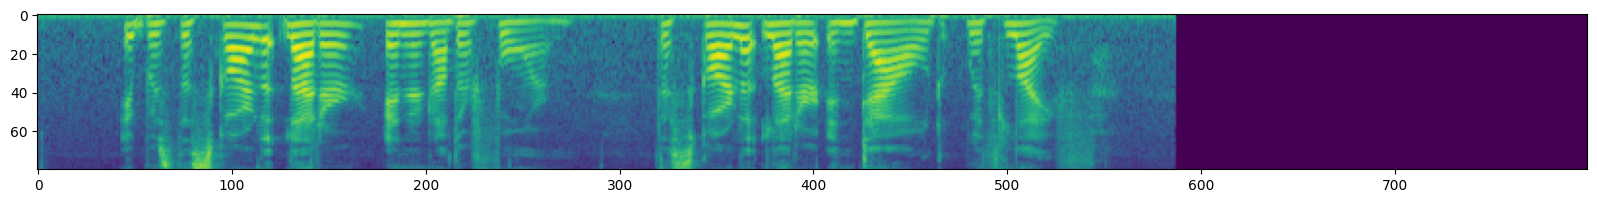

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 20))
imshow(audio_features.to(torch.float32)[0][:,:800].cpu().numpy())

In [15]:
plt.figure(figsize=(20, 20))

outs = model.audio_encoder(audio_features).last_hidden_state.to(torch.float32).cpu().numpy()

<Figure size 2000x2000 with 0 Axes>

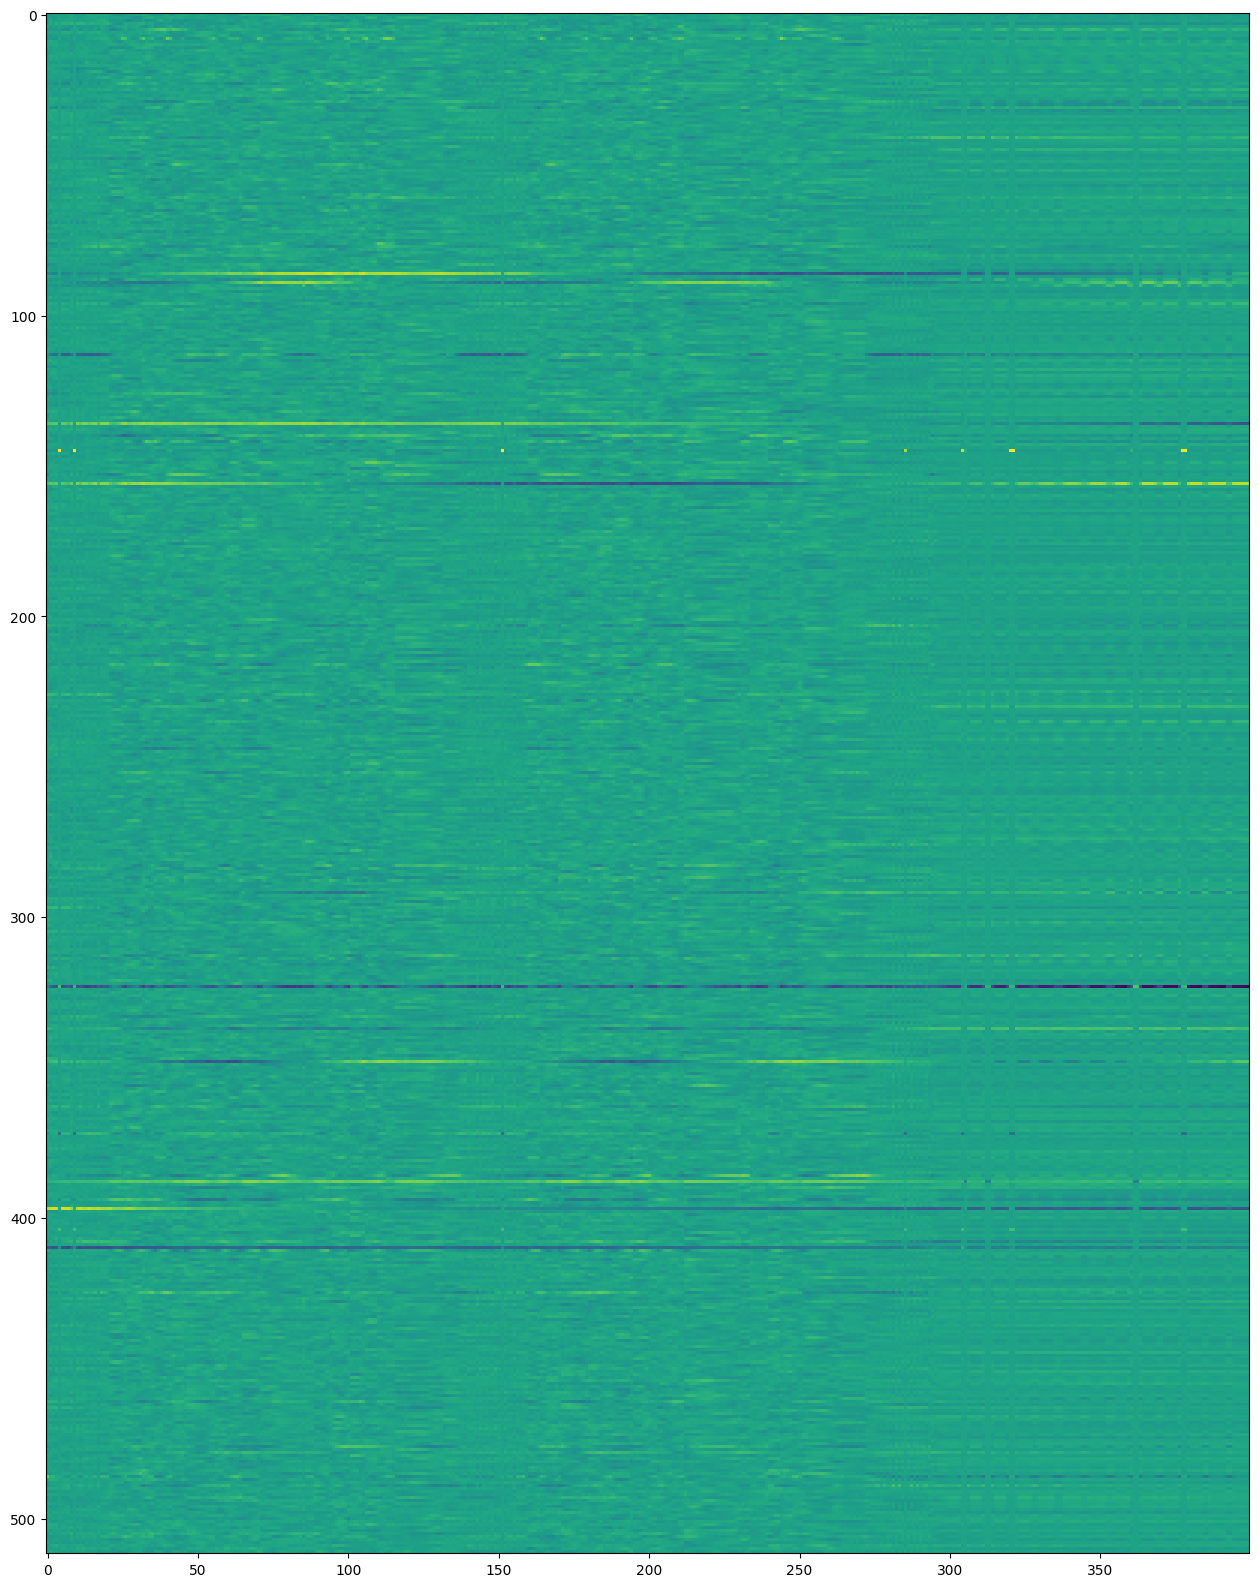

In [16]:
plt.figure(figsize=(20, 20))

imshow(outs[0].T[:,:400])

In [17]:
outs = model.audio_encoder(audio_features, output_attentions=True)

WhisperModel is using WhisperSdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `layer_head_mask` not None. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


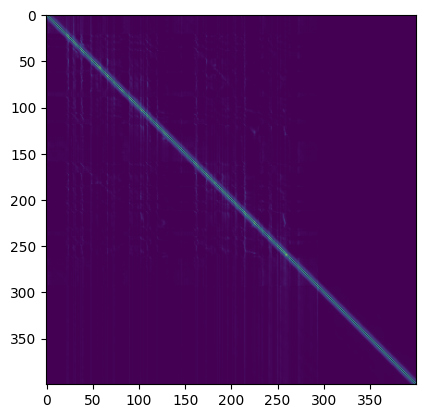

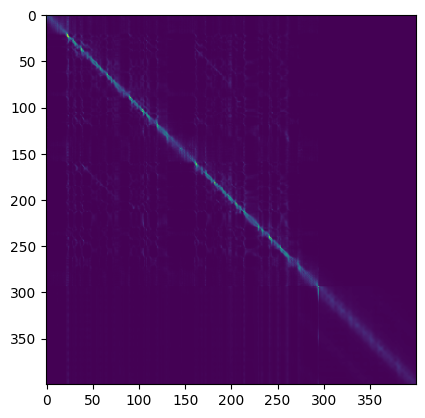

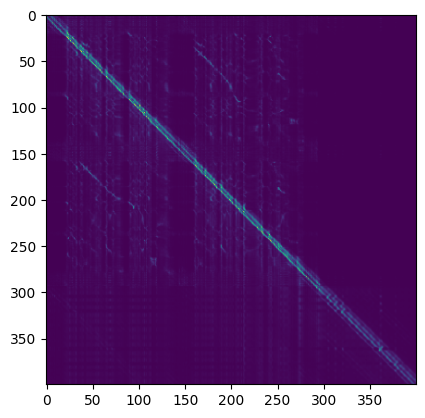

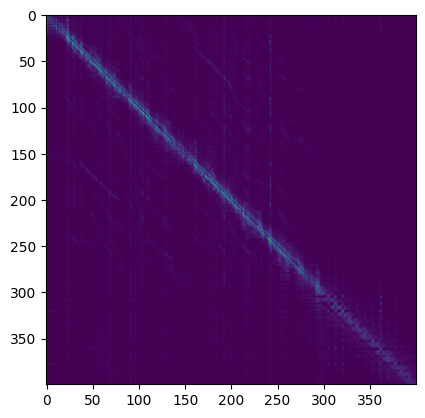

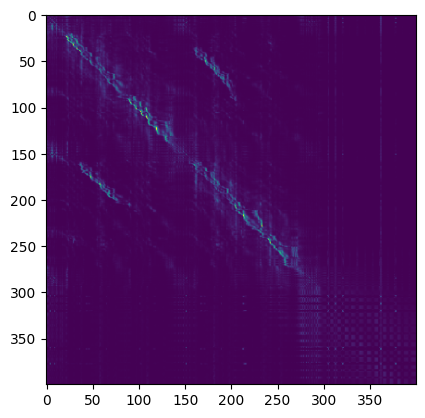

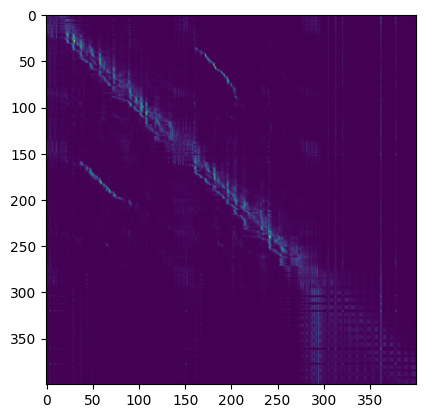

In [32]:

for attn in outs.attentions:
    imshow(attn.mean(dim=1)[0][:400,:400].to(torch.float32).cpu().numpy())
    plt.show()

In [34]:
outs = model.audio_encoder(audio_features)
proj_outs = model.projector(outs.last_hidden_state)

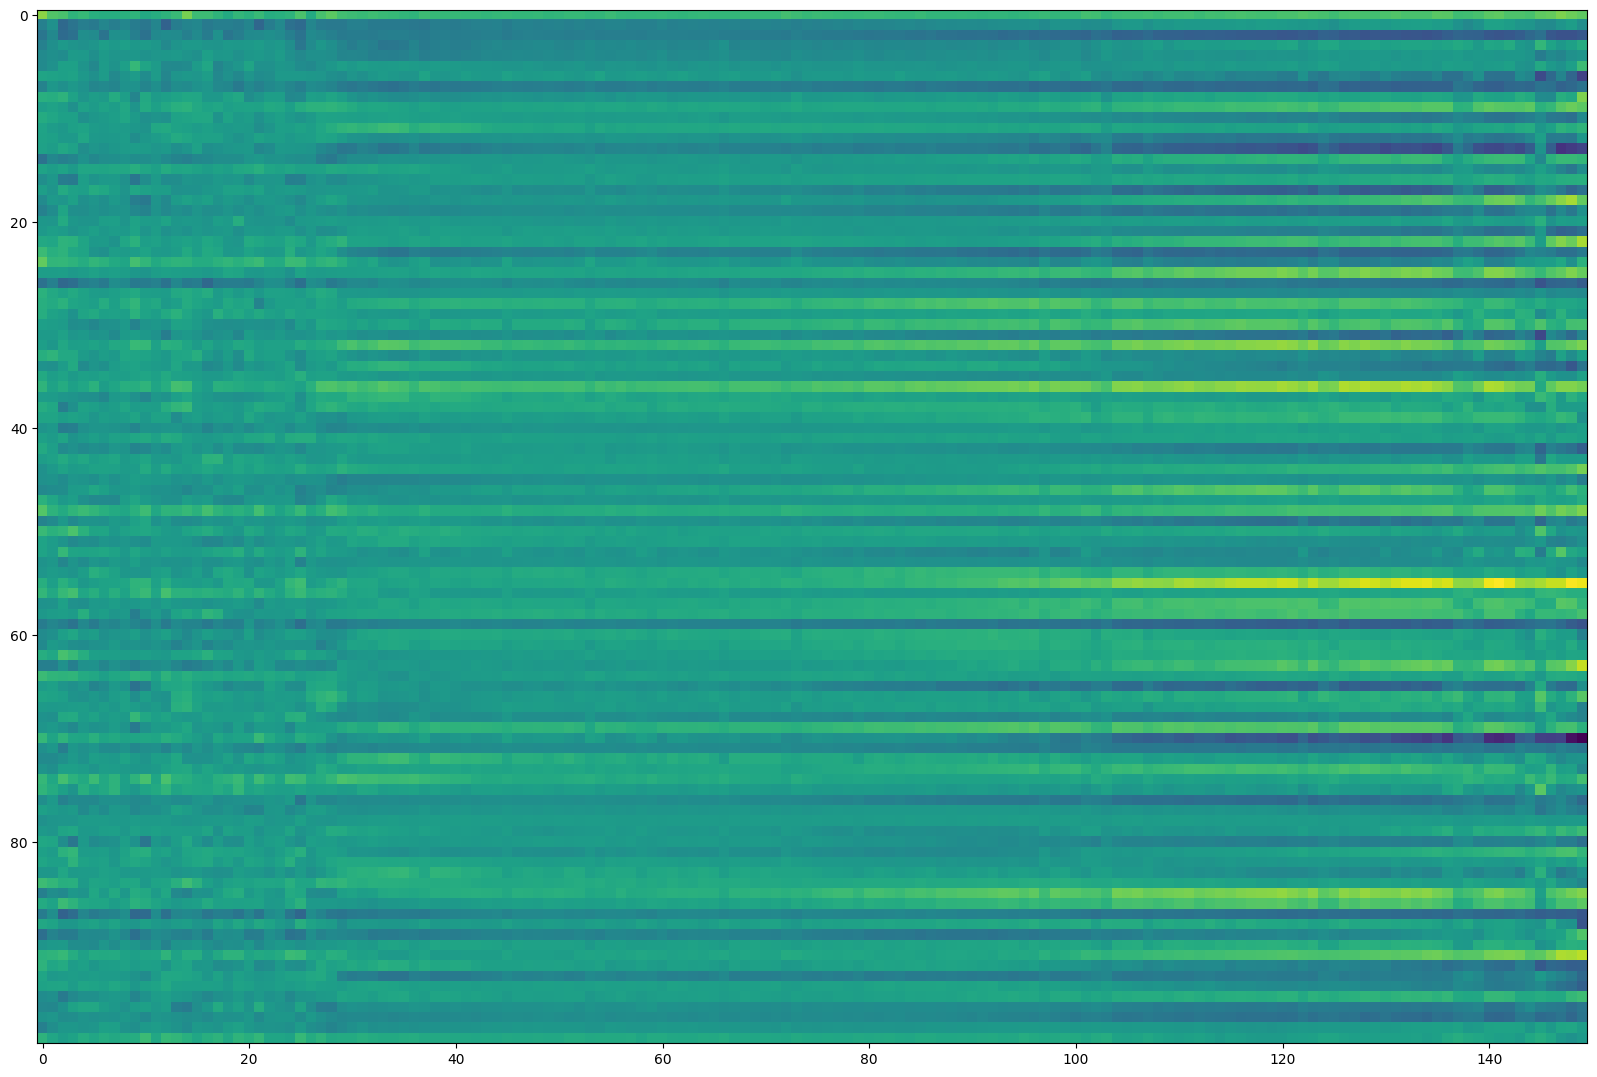

In [58]:
plt.figure(figsize=(20, 20))
imshow(proj_outs[0][:600, :100].T.to(torch.float32).cpu().numpy())